# Résultats des entraînements

Courbes tirées des `log.txt` des runs (format MimicKit, aussi écrit par `rl/train.py`, une ligne toutes les
50 itérations). On peut relancer le notebook à tout moment, y compris pendant un run : il ne fait que lire
les logs. Une section par run de la série 1, les comparaisons de la série 1, puis les séries 2 à 6.
Numérotation : série N = configs `configs/runN/` (voir `configs/README.md`) = sorties
`outputs/rl/amp_<tâche>_N` (série 1 : sans suffixe). Chaque run enregistre ses figures dans son dossier
(`training_curves.png`, et `amp_curves.png` pour les runs AMP).

À lancer depuis la racine du repo, avec le kernel du venv du projet.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT = Path.cwd()
EP_STEPS = 600                                   # 20 s at 30 Hz

RUNS = {                                         # key -> (label, run dir); the order fixes the colors
    "ppo_mimickit": ("PPO de MimicKit (Antoine)", "outputs/phase3/ppo_heading"),
    "ppo_rl": ("PPO de rl/ (Roman)", "outputs/rl/ppo_heading"),
    "walk_1": ("AMP Walk, série 1", "outputs/rl/amp_walk"),
    "run_1": ("AMP Run, série 1", "outputs/rl/amp_run"),
    "locomotion_1": ("AMP Locomotion, série 1", "outputs/rl/amp_locomotion"),
}
COLORS = dict(zip(RUNS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))   # categorical, fixed order
PAIR = ["#2a78d6", "#eb6834"]                    # two series inside one run's figure
INK, GRID = "#3a3a38", "#e4e3df"


def read_log(path):
    """MimicKit's text log: a header line, then one row of values per output iteration."""
    tokens = Path(path).read_text().split()
    ncol = next(i for i, t in enumerate(tokens) if _is_number(t))
    header, values = tokens[:ncol], tokens[ncol:]
    nrow = len(values) // ncol
    data = np.array(values[:nrow * ncol], dtype=float).reshape(nrow, ncol)
    return {k: data[:, i] for i, k in enumerate(header)}


def _is_number(s):
    try:
        float(s)
        return True
    except ValueError:
        return False


def load(key):
    """Log of a run, or None (with a message) if it has no log.txt yet."""
    label, run_dir = RUNS[key]
    path = PROJECT / run_dir / "log.txt"
    if not path.exists():
        print(f"{label} : pas encore de log.txt")
        return None
    log = read_log(path)
    print(f"{label} : {len(log['Samples'])} lignes, {log['Samples'][-1] / 1e6:.0f} M échantillons, "
          f"{log['Wall_Time'][-1]:.2f} h, {log['Samples_Per_Second'][-1]:.0f} échantillons/s ; "
          f"dernier test : retour normalisé {log['Test_Return'][-1] / EP_STEPS:.3f}, "
          f"épisodes {log['Test_Episode_Length'][-1] / 30:.1f} s")
    return log


def style(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel, color=INK)
    ax.set_ylabel(ylabel, color=INK)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=INK)


def plot_training(key, log):
    """Return and episode length, train (sampled actions) and test (mean action)."""
    label, run_dir = RUNS[key]
    s = log["Samples"] / 1e6
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for (prefix, name), color in zip([("Test", "test"), ("Train", "entraînement")], PAIR):
        axes[0].plot(s, log[f"{prefix}_Return"] / EP_STEPS, color=color, linewidth=2, label=name)
        axes[1].plot(s, log[f"{prefix}_Episode_Length"] / 30, color=color, linewidth=2, label=name)
    style(axes[0], "échantillons (M)", "retour de tâche normalisé")
    style(axes[1], "échantillons (M)", "durée des épisodes (s)")
    axes[0].set_ylim(0, 1)
    axes[1].set_ylim(0, 20.5)
    axes[0].legend(frameon=False, loc="lower right")
    fig.suptitle(label, color=INK)
    fig.tight_layout()
    fig.savefig(PROJECT / run_dir / "training_curves.png", dpi=110)
    plt.show()


def plot_amp(key, log):
    """Rewards and discriminator of an AMP run."""
    label, run_dir = RUNS[key]
    s = log["Samples"] / 1e6
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    panels = [
        (axes[0, 0], [("Task_Reward_Mean", "r_G (tâche)"), ("Style_Reward_Mean", "r_S (style)")],
         "récompense moyenne par pas", (0, 1)),
        (axes[0, 1], [("Disc_Acc_Mocap", "mocap jugée mocap"), ("Disc_Acc_Agent", "agent jugé agent")],
         "précision de D", (0, 1.02)),
        (axes[1, 0], [("Disc_Loss", "perte LSGAN (éq. 6)")], "perte de D", None),
        (axes[1, 1], [("Disc_Grad_Penalty", "pénalité de gradient (éq. 8)")], "pénalité de gradient", None),
    ]
    for ax, cols, ylabel, ylim in panels:
        for (col, name), color in zip(cols, PAIR):
            if col in log:
                ax.plot(s, log[col], color=color, linewidth=2, label=name)
        style(ax, "échantillons (M)", ylabel)
        if ylim:
            ax.set_ylim(*ylim)
        if len(cols) > 1:
            ax.legend(frameon=False)
        else:
            ax.set_title(cols[0][1], color=INK, fontsize=10)
    axes[0, 1].axhline(0.5, color="#8a8980", linewidth=1, linestyle="--")
    fig.suptitle(f"{label} : discriminateur", color=INK)
    fig.tight_layout()
    fig.savefig(PROJECT / run_dir / "amp_curves.png", dpi=110)
    plt.show()


def show_run(key):
    log = load(key)
    if log is None:
        return None
    plot_training(key, log)
    if "Disc_Acc_Mocap" in log:
        plot_amp(key, log)
    return log


logs = {}

## PPO de MimicKit (Antoine)

PPO seul (r_G), code de MimicKit (`amp/run.py`), `outputs/phase3/ppo_heading`.

PPO de MimicKit (Antoine) : 47 lignes, 300 M échantillons, 3.55 h, 23503 échantillons/s ; dernier test : retour normalisé 0.913, épisodes 19.6 s


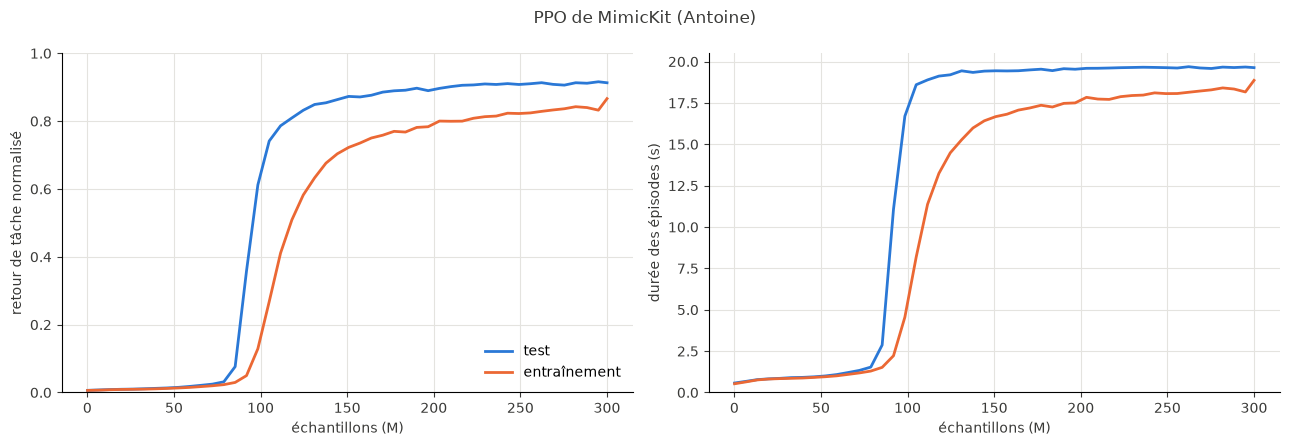

In [2]:
logs["ppo_mimickit"] = show_run("ppo_mimickit")

## PPO de `rl/` (Roman)

Même expérience avec notre PPO (`rl/train.py`), `outputs/rl/ppo_heading`.

PPO de rl/ (Roman) : 47 lignes, 300 M échantillons, 3.73 h, 22365 échantillons/s ; dernier test : retour normalisé 0.918, épisodes 19.7 s


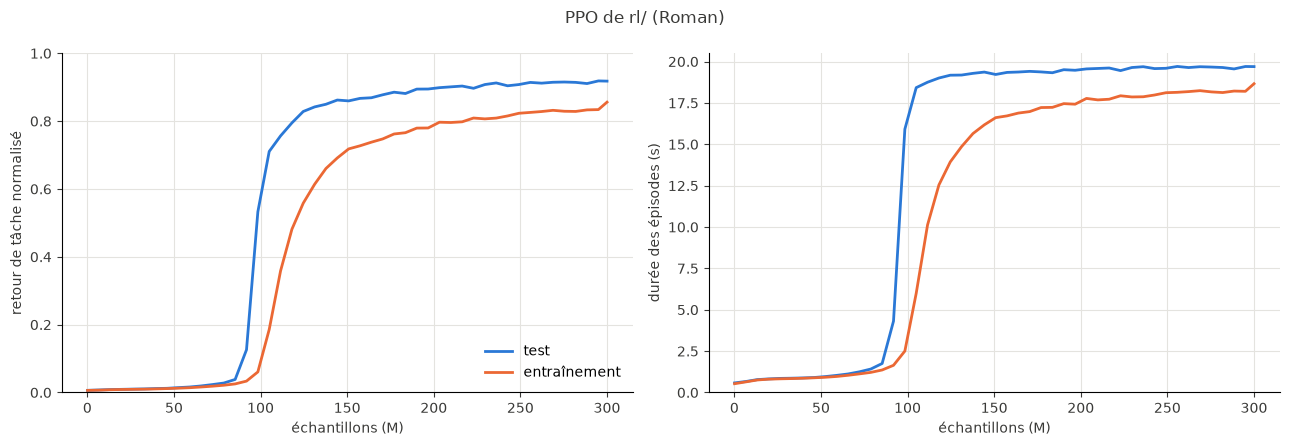

In [3]:
logs["ppo_rl"] = show_run("ppo_rl")

## Série 1 : AMP Walk

AMP de `rl/`, jeu de données Walk (9 clips), `outputs/rl/amp_walk`.

Repères AMP (`rl/README.md`) : précisions de D entre ~0,55 et ~0,95 (collées à 1 : D a gagné, r_S tombe à 0 ; collées à 0,5 : D n'apprend rien), r_S qui baisse au début puis remonte, pénalité de gradient petite et stable, r_G qui monte comme en PPO, sans doute plus lentement.

AMP Walk, série 1 : 47 lignes, 300 M échantillons, 4.77 h, 17488 échantillons/s ; dernier test : retour normalisé 0.818, épisodes 20.0 s


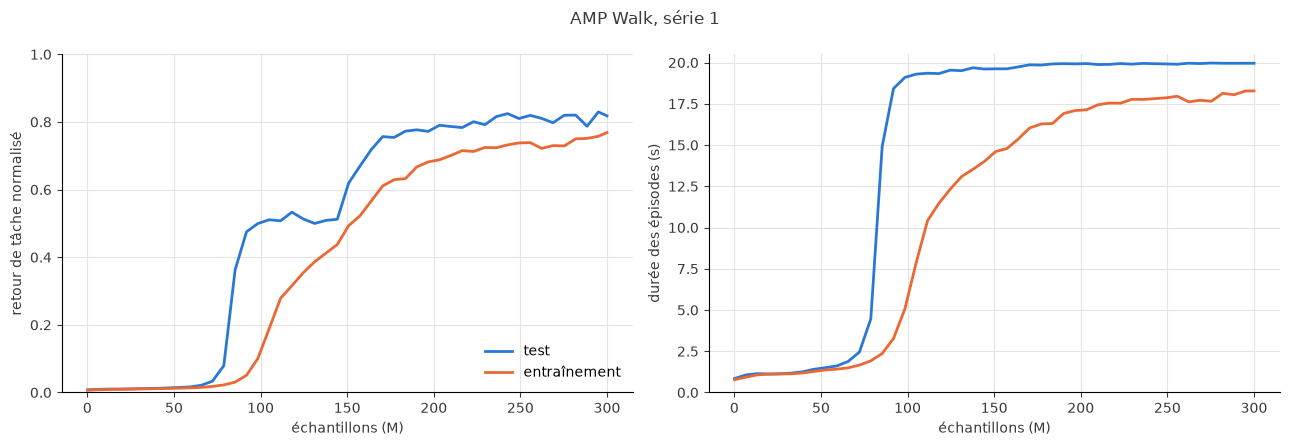

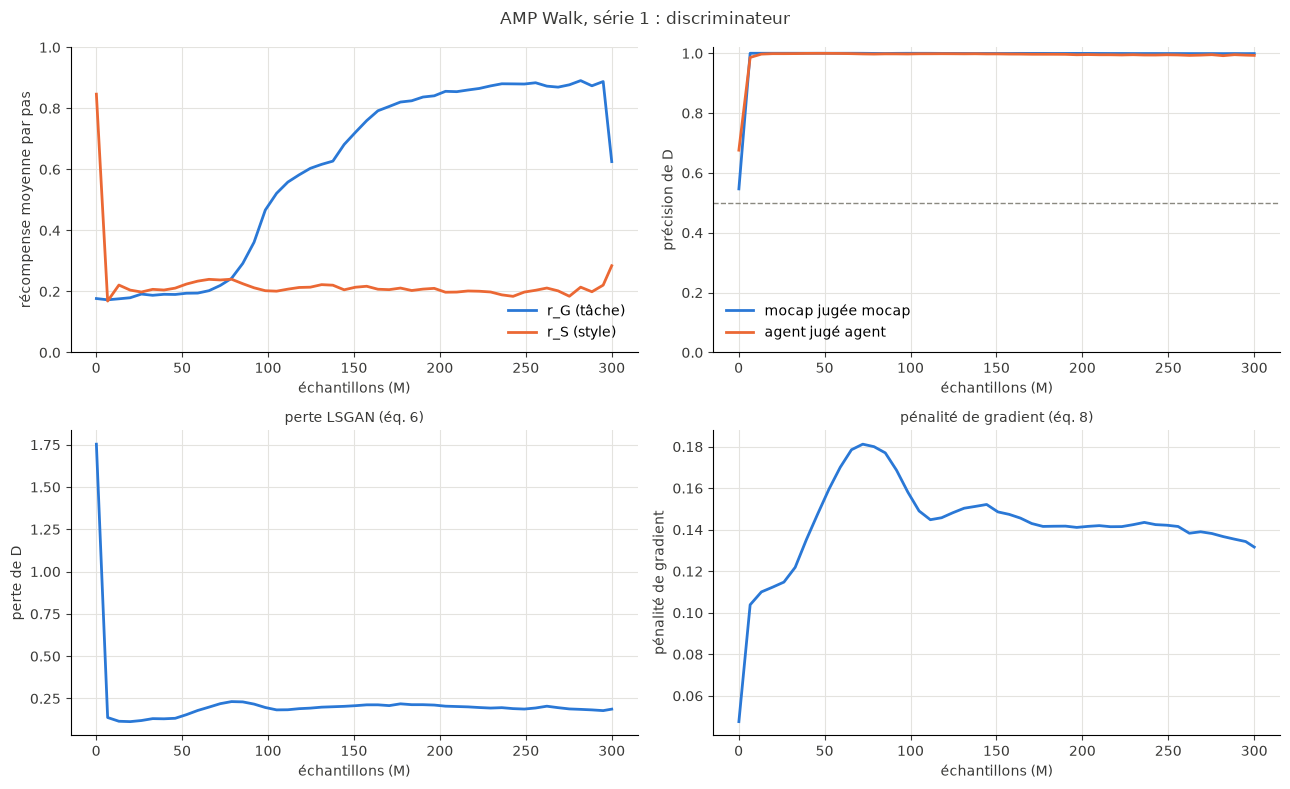

In [4]:
logs["walk_1"] = show_run("walk_1")

## Série 1 : AMP Run

AMP de `rl/`, jeu de données Run, `outputs/rl/amp_run`.

AMP Run, série 1 : 47 lignes, 300 M échantillons, 4.59 h, 18159 échantillons/s ; dernier test : retour normalisé 0.900, épisodes 19.6 s


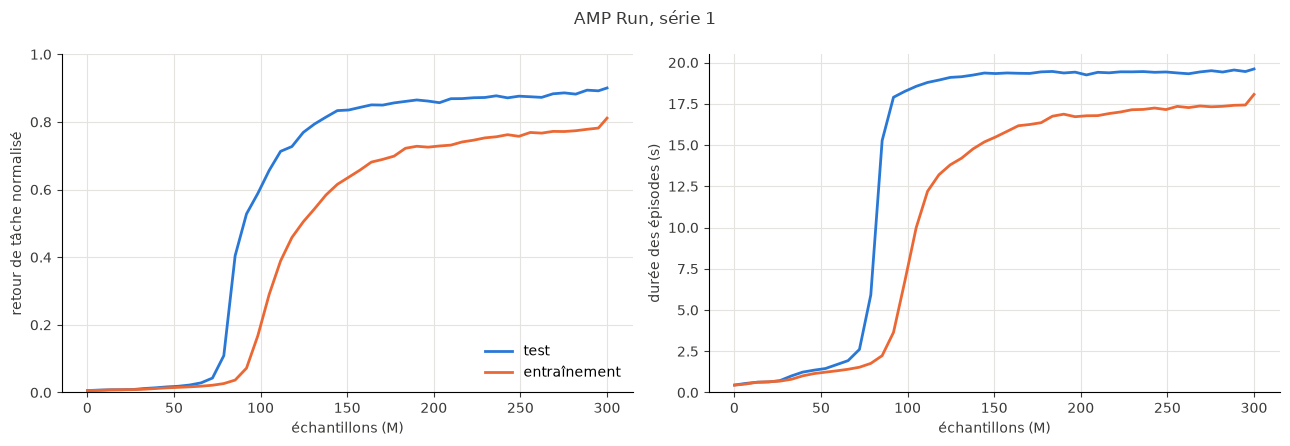

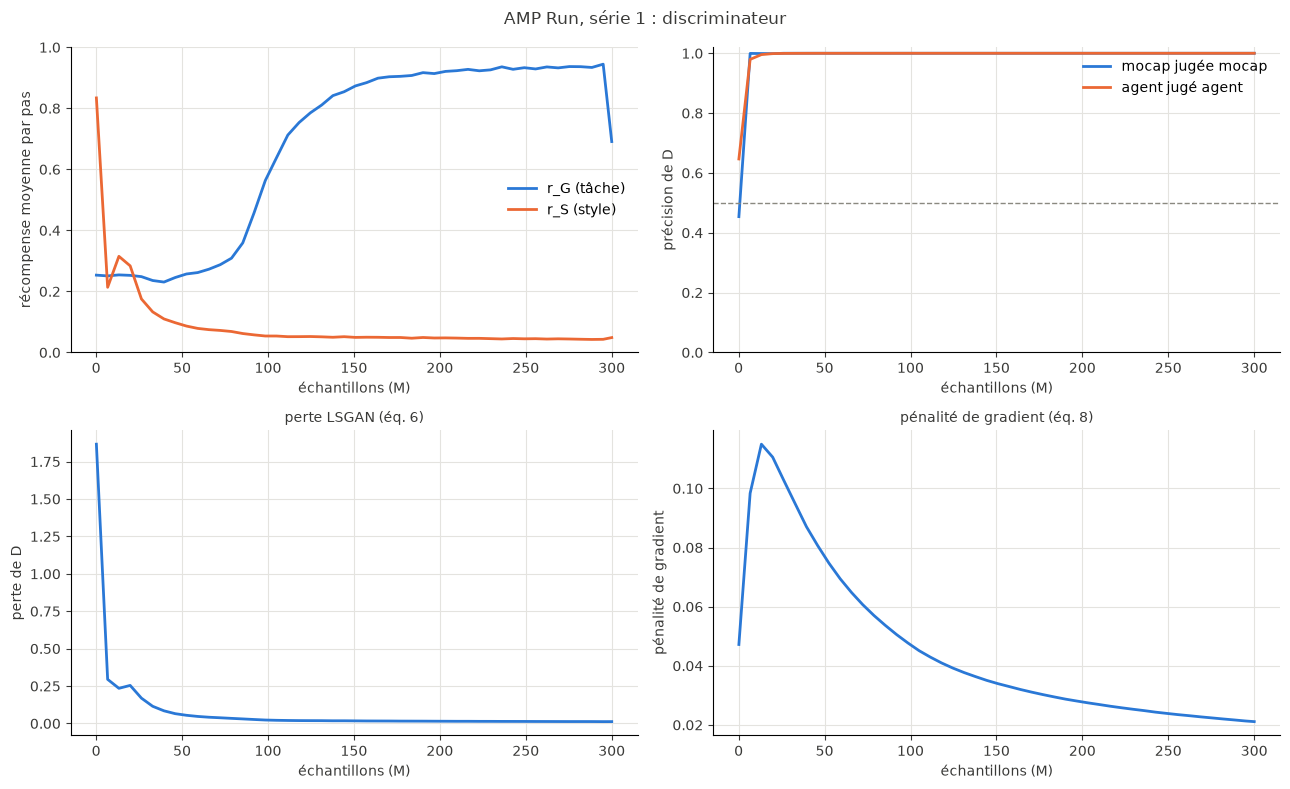

In [5]:
logs["run_1"] = show_run("run_1")

## Série 1 : AMP Locomotion

AMP de `rl/`, Walk + Run (56 clips), `outputs/rl/amp_locomotion`.

AMP Locomotion, série 1 : 47 lignes, 300 M échantillons, 4.45 h, 18738 échantillons/s ; dernier test : retour normalisé 0.873, épisodes 19.7 s


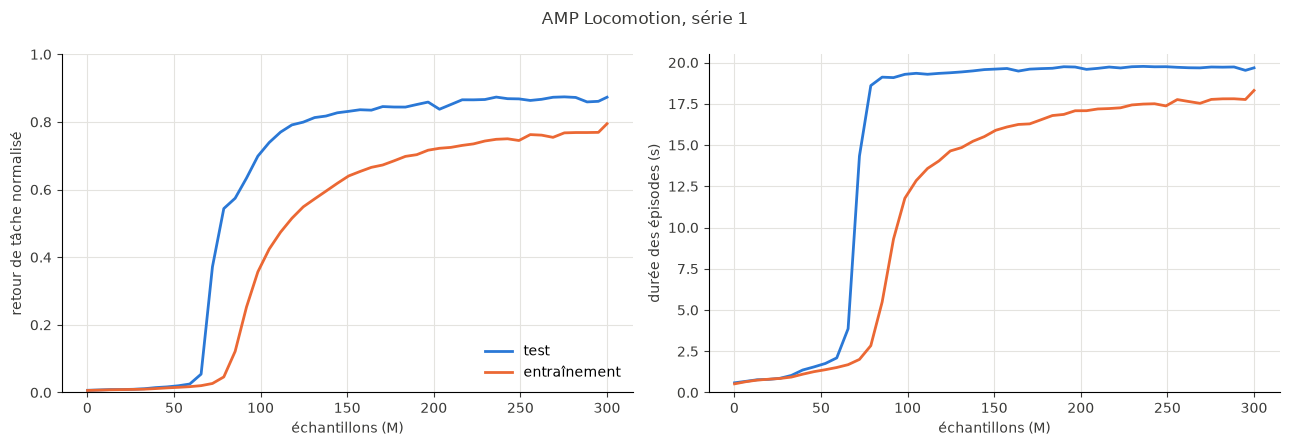

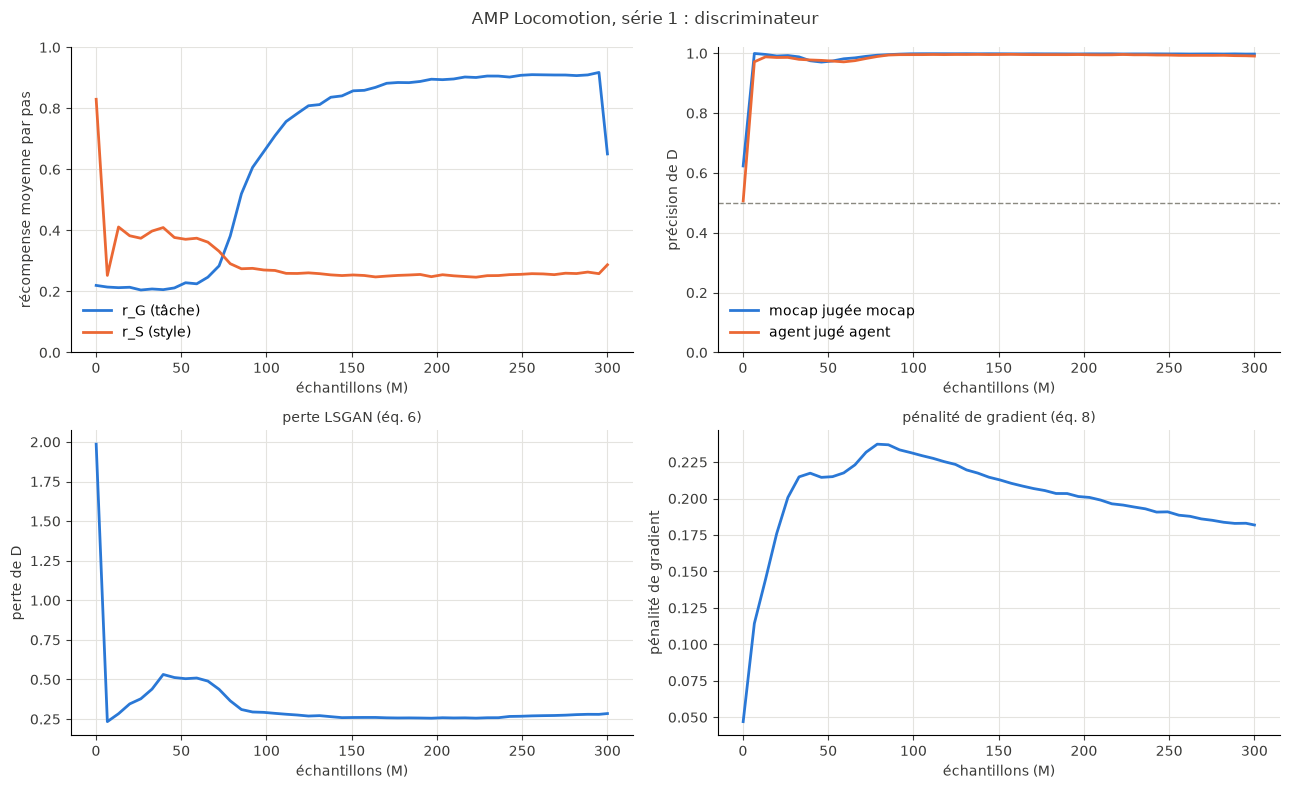

In [6]:
logs["locomotion_1"] = show_run("locomotion_1")

## Série 1 : comparaison des runs, épisodes de test pendant l'entraînement

Retour de tâche normalisé = somme de r_G sur l'épisode / 600 (entre 0 et 1 ; pour les runs AMP, r_G seul,
donc comparable au PPO seul). Durée des épisodes : 20 s au maximum.

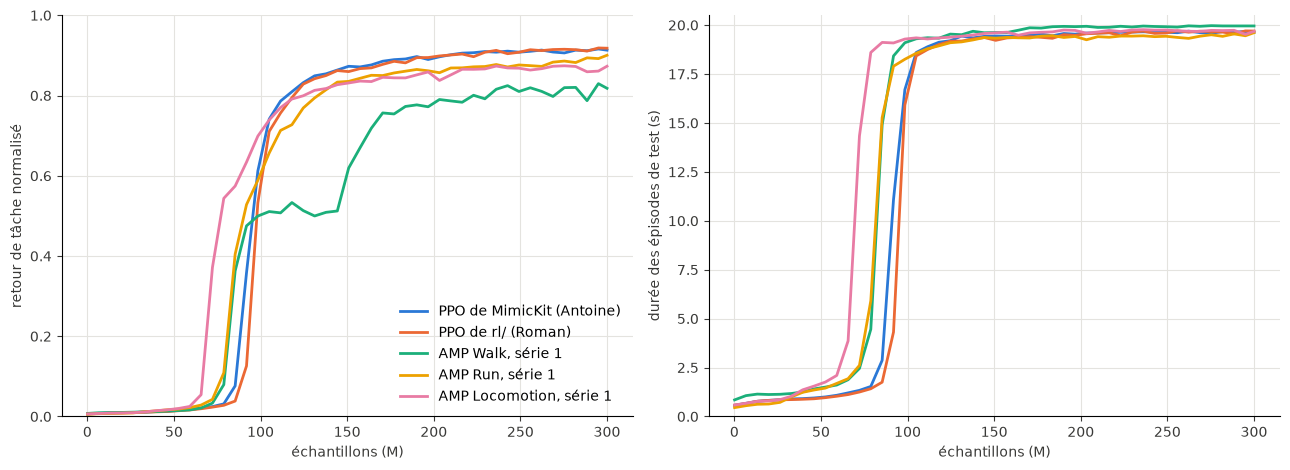

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for key, log in logs.items():
    if log is None:
        continue
    s = log["Samples"] / 1e6
    axes[0].plot(s, log["Test_Return"] / EP_STEPS, color=COLORS[key], linewidth=2, label=RUNS[key][0])
    axes[1].plot(s, log["Test_Episode_Length"] / 30, color=COLORS[key], linewidth=2, label=RUNS[key][0])
style(axes[0], "échantillons (M)", "retour de tâche normalisé")
style(axes[1], "échantillons (M)", "durée des épisodes de test (s)")
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 20.5)
axes[0].legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(PROJECT / "outputs" / "runs_comparison.png", dpi=110)
plt.show()

## PPO de MimicKit contre PPO de `rl/`

Même expérience : le décollage et le plateau doivent coïncider, au bruit près (une seule graine de chaque côté).

In [8]:
def first_crossing(log, col, value):
    """Samples (M) at the first log row where col >= value, or None."""
    idx = np.nonzero(log[col] >= value)[0]
    return log["Samples"][idx[0]] / 1e6 if len(idx) else None

for key in ("ppo_mimickit", "ppo_rl"):
    label, log = RUNS[key][0], logs.get(key)
    if log is None:
        print(f"{label:30s} pas encore de log")
        continue
    t10 = first_crossing(log, "Test_Episode_Length", 10 * 30)
    last = slice(-5, None)                     # mean of the last 5 rows (~30 M samples)
    print(f"{label:30s} épisodes > 10 s à {'%.0f M' % t10 if t10 else 'pas encore'}, "
          f"fin : retour {log['Test_Return'][last].mean() / EP_STEPS:.3f}, "
          f"épisodes {log['Test_Episode_Length'][last].mean() / 30:.1f} s, "
          f"{log['Samples_Per_Second'][-1]:.0f} échantillons/s")

PPO de MimicKit (Antoine)      épisodes > 10 s à 92 M, fin : retour 0.912, épisodes 19.6 s, 23503 échantillons/s
PPO de rl/ (Roman)             épisodes > 10 s à 98 M, fin : retour 0.915, épisodes 19.7 s, 22365 échantillons/s


## Séries 2 à 6 : le discriminateur sur Run

En série 1, AMP Run atteint la tâche mais r_S s'effondre : D reconnaît presque toutes les transitions de
l'agent (D ≈ −1, r_S ≈ 0), ce qui n'arrive ni sur Walk ni sur Locomotion. Les séries suivantes
cherchent la cause. Configs : `configs/runN/`, différences détaillées dans `configs/README.md`.

| Série | Changement | Runs |
|---|---|---|
| 1 | AMP de l'article, `disc_steps` 32 | walk, run, locomotion |
| 2 | `disc_steps` 8 (D entraîné 4× moins) | run ; walk arrêté à 79 M |
| 3 | série 2 + régularisation de D façon MimicKit (weight decay 1e-4, pénalité 0,01 sur la dernière couche) | walk, run, locomotion |
| 4 | série 2 + pas de la politique de l'article (4e-6 au lieu de 5e-5) + pieds de la mocap alignés sur le sol | run, arrêté à 85 M |
| 5 | série 2 + pieds alignés + entrées de Φ constantes dans la mocap masquées pour D (le cou de Run) | en cours |
| 6 | série 2 + pieds alignés + normaliseur de D sur agent + mocap, comme MimicKit | à venir |

Diagnostic (entre les séries 4 et 5) : dans les 47 clips Run, le cou vaut exactement 0 sur toutes les
frames. Avec un normaliseur de D calculé sur la mocap seule, son écart-type est au plancher (1e-4) et
le moindre mouvement du cou de l'agent (1 à 2°) arrive à ±10 en entrée de D : un indice parfait que
l'agent ne peut pas effacer. Les séries 5 et 6 testent deux corrections.

Ce qu'on regarde : r_S moyen et D moyen sur l'agent. Effondrement = r_S qui tombe vers 0,05 et D vers −1
entre 13 et 90 M échantillons. Le retour de tâche (test) vérifie que la tâche reste apprise. Les runs
en cours ou arrêtés s'affichent jusqu'où ils sont allés.

In [9]:
SERIES = [1, 2, 3, 4, 5, 6]
SERIES_COLORS = dict(zip(SERIES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))  # categorical, fixed order
TASKS = {"walk": "Walk", "run": "Run", "locomotion": "Locomotion"}


def series_dir(task, n):
    return PROJECT / "outputs" / "rl" / (f"amp_{task}" if n == 1 else f"amp_{task}_{n}")


def read_series(task):
    """{series: log} for the runs of this task that have a log.txt."""
    out = {}
    for n in SERIES:
        path = series_dir(task, n) / "log.txt"
        if path.exists():
            out[n] = read_log(path)
    return out


def plot_series(task):
    """One figure per task: the series side by side, 4 panels. Saved to outputs/series_<task>.png."""
    logs_t = read_series(task)
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
    panels = [
        (axes[0, 0], lambda l: l["Test_Return"] / EP_STEPS, "retour de tâche normalisé (test)", (0, 1)),
        (axes[0, 1], lambda l: l["Style_Reward_Mean"], "r_S moyen (style)", (0, 1)),
        (axes[1, 0], lambda l: l["Disc_Agent_Mean"], "D moyen sur l'agent (−1 : reconnu)", (-1.05, 1.05)),
        (axes[1, 1], lambda l: l["Disc_Acc_Agent"], "précision de D sur l'agent", (0, 1.02)),
    ]
    for ax, f, ylabel, ylim in panels:
        for n, log in logs_t.items():
            ax.plot(log["Samples"] / 1e6, f(log), color=SERIES_COLORS[n], linewidth=2, label=f"série {n}")
        style(ax, "échantillons (M)", ylabel)
        ax.set_ylim(*ylim)
    axes[1, 0].axhline(0, color="#8a8980", linewidth=1, linestyle="--")
    axes[0, 1].legend(frameon=False, loc="upper right")
    fig.suptitle(f"AMP {TASKS[task]} : séries {', '.join(map(str, logs_t))}", color=INK)
    fig.tight_layout()
    fig.savefig(PROJECT / "outputs" / f"series_{task}.png", dpi=110)
    plt.show()
    return logs_t


series_logs = {}

### Run

La tâche où r_S s'effondre. Séries 1 à 3 : même trajectoire de D, la série 2 retarde à peine
l'effondrement. Série 4 : la tâche est beaucoup plus lente, mais D sépare l'agent au même rythme.

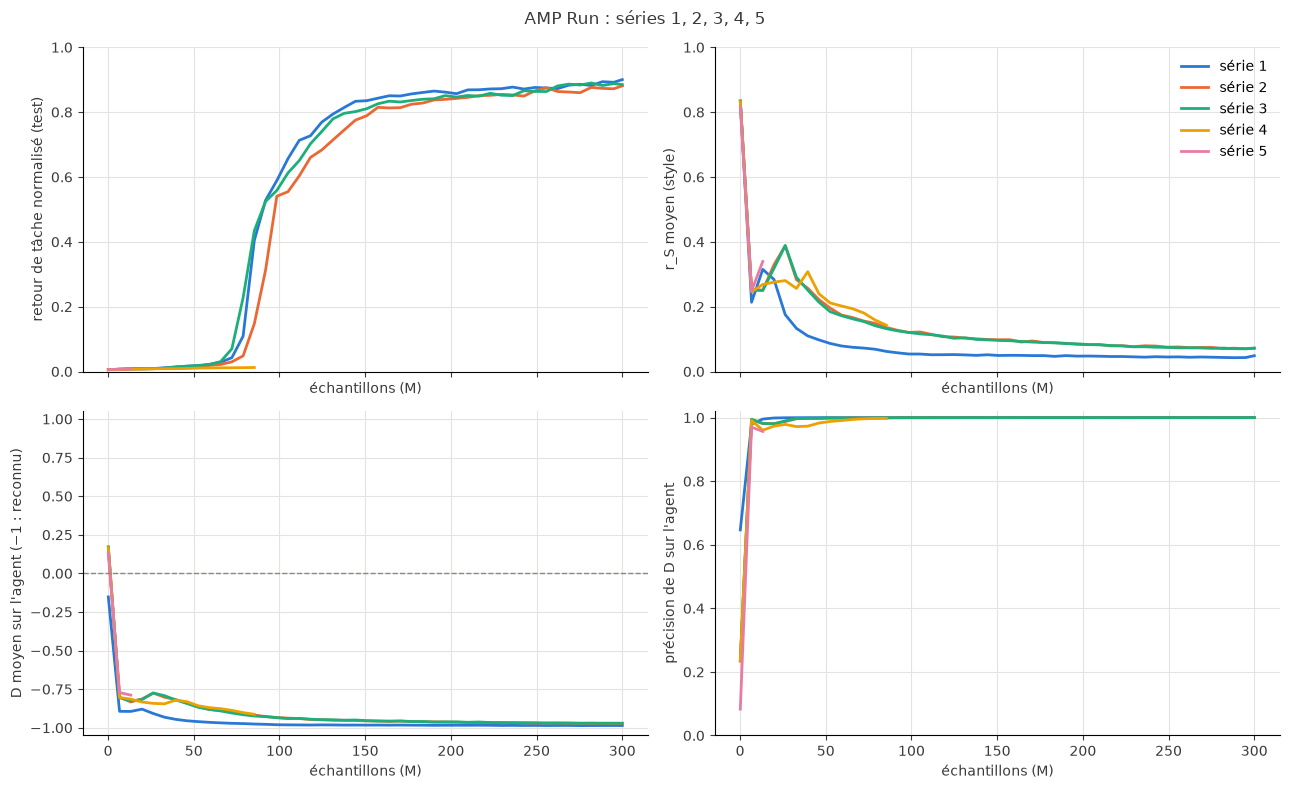

In [10]:
series_logs["run"] = plot_series("run")

### Walk

Pas d'effondrement en série 1 : sert de témoin (les corrections ne doivent pas dégrader Walk).

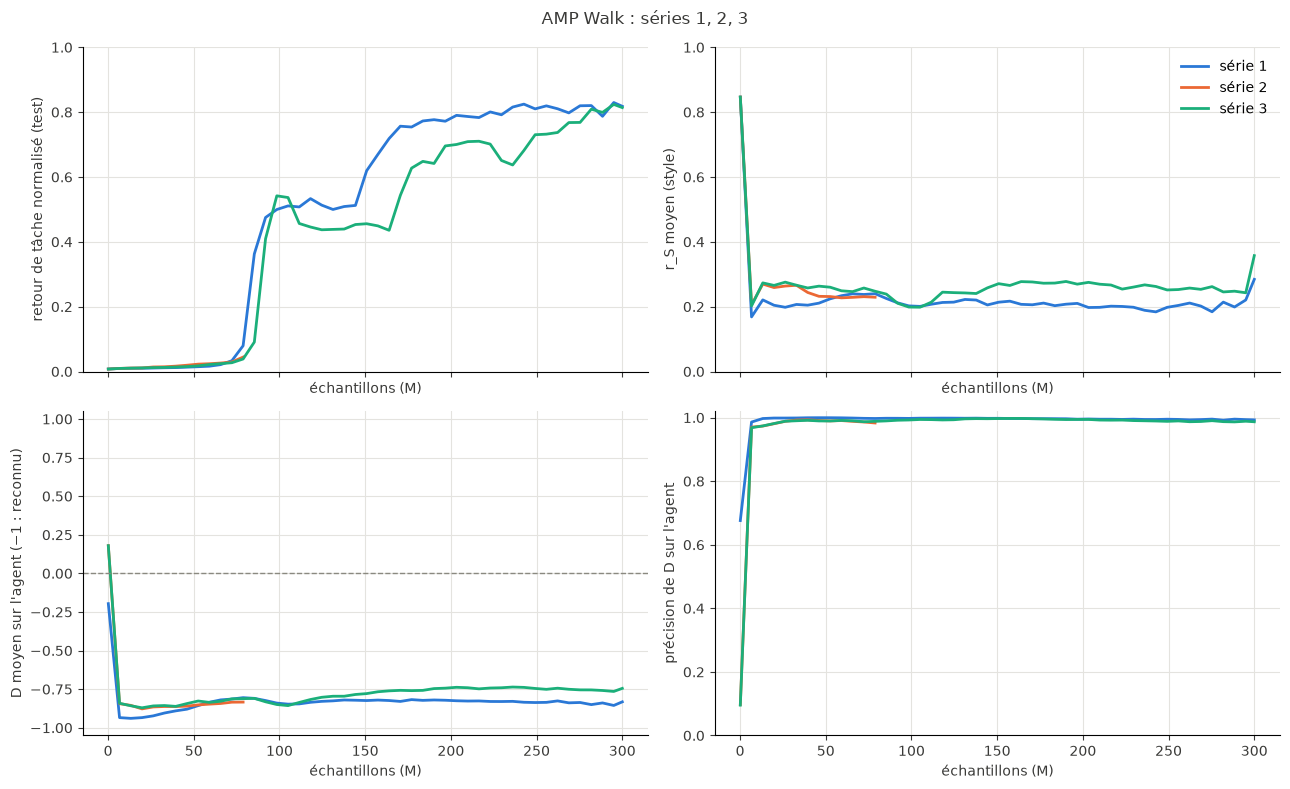

In [11]:
series_logs["walk"] = plot_series("walk")

### Locomotion

Walk + Run (56 clips) : les clips de longue marche ont un cou mobile, donc pas d'indice parfait.

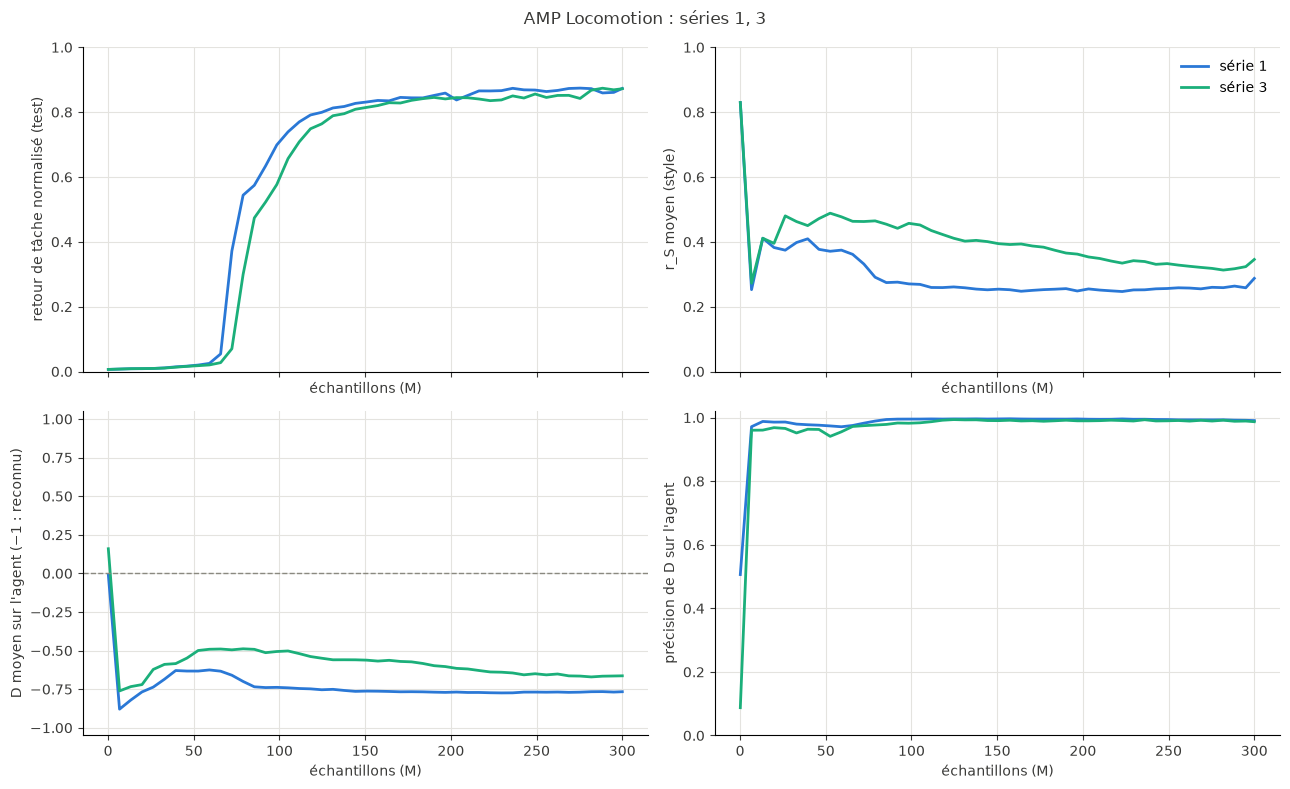

In [12]:
series_logs["locomotion"] = plot_series("locomotion")

### Tableau récapitulatif

r_S et D aux jalons 20, 50 et 90 M (ligne de log la plus proche, « - » si le run s'est arrêté avant), et à
la fin (moyenne des 5 dernières lignes de log).

In [13]:
def at(log, col, m):
    """Value of col at the log row closest to m million samples, or None if the run stopped before."""
    s = log["Samples"] / 1e6
    if s[-1] < m - 1:
        return None
    return log[col][np.abs(s - m).argmin()]


def fmt(x, spec):
    width = int(spec.split(".")[0].lstrip("+"))
    return format(x, spec) if x is not None else "-".rjust(width)


print(f"{'run':18s} {'éch.':>5s} | {'r_S 20M':>7s} {'50M':>6s} {'90M':>6s} {'fin':>6s} | "
      f"{'D agent 50M':>11s} {'fin':>6s} | {'retour fin':>10s}")
for task, logs_t in series_logs.items():
    for n, log in logs_t.items():
        last = slice(-5, None)
        print(f"{series_dir(task, n).name:18s} {log['Samples'][-1] / 1e6:4.0f}M | "
              f"{fmt(at(log, 'Style_Reward_Mean', 20), '7.3f')} {fmt(at(log, 'Style_Reward_Mean', 50), '6.3f')} "
              f"{fmt(at(log, 'Style_Reward_Mean', 90), '6.3f')} {log['Style_Reward_Mean'][last].mean():6.3f} | "
              f"{fmt(at(log, 'Disc_Agent_Mean', 50), '+11.2f')} {log['Disc_Agent_Mean'][last].mean():+6.2f} | "
              f"{log['Test_Return'][last].mean() / EP_STEPS:10.3f}")
    print()

run                 éch. | r_S 20M    50M    90M    fin | D agent 50M    fin | retour fin
amp_run             300M |   0.284  0.087  0.058  0.044 |       -0.96  -0.99 |      0.891
amp_run_2           300M |   0.329  0.195  0.127  0.072 |       -0.86  -0.97 |      0.873
amp_run_3           300M |   0.318  0.184  0.125  0.071 |       -0.87  -0.97 |      0.886
amp_run_4            85M |   0.276  0.211      -  0.176 |       -0.86  -0.89 |      0.012
amp_run_5            13M |       -      -      -  0.468 |           -  -0.48 |      0.007

amp_walk            300M |   0.204  0.224  0.212  0.220 |       -0.86  -0.84 |      0.815
amp_walk_2           79M |   0.259  0.231      -  0.229 |       -0.85  -0.84 |      0.029
amp_walk_3          300M |   0.266  0.260  0.211  0.271 |       -0.83  -0.76 |      0.803

amp_locomotion      300M |   0.382  0.371  0.276  0.265 |       -0.63  -0.77 |      0.868
amp_locomotion_3    300M |   0.395  0.488  0.442  0.323 |       -0.50  -0.67 |      0.865

